# Bài 8 — Connect 4: notebook tích hợp của Ly

Thành viên phụ trách notebook: Ly. Công cụ hỗ trợ: OpenAI Codex (cài đặt, đo và kiểm thử). Người nộp cần tự đọc và xác nhận nội dung. Module core: Hải; search: Thiện; Monte Carlo và tích hợp: Ly.

Phạm vi: Task 1–5; không làm Graduate/bonus. Run All từ thư mục Lab 05. Thời gian dùng `perf_counter`, warm-up không tính vào bảng; không đo render.

## Task 1 — Search problem

- Initial state: mảng 6×7 toàn 0; +1 đi trước, −1 đi sau.
- Actions: chỉ số cột chưa đầy, từ 0.
- Transition: quân rơi xuống ô trống thấp nhất của cột; trả bàn mới.
- Terminal: có bốn quân cùng màu ngang/dọc/chéo hoặc hết ô. Utility theo player là +1/0/−1; chưa kết thúc là `None`.

Dùng mảng số nguyên NumPy 0,1,−1 theo contract nhóm. Các thuật toán được import từ module tương ứng.

{'Python': '3.13.5', 'seed': 42, 'rules_backend': 'connect4_search fallback (core integration pending)'}


**Tích hợp core đang chờ:** chưa có `connect4_core.py` của Hải. Các số liệu dưới đây dùng adapter luật dự phòng đã có trong `connect4_search.py` của Thiện; không thay thế kiểm thử với core chính thức. Không sao chép luật hoặc thuật toán vào notebook.

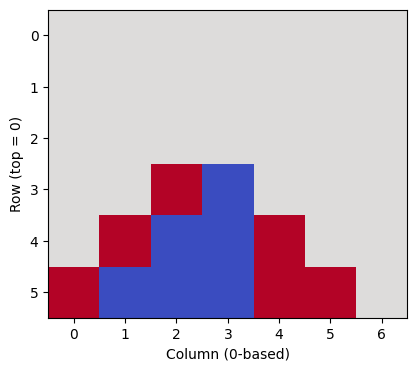

In [1]:
from pathlib import Path
from time import perf_counter
import platform
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
import connect4_search as search
from connect4_monte_carlo import pmcs, playout, PureMonteCarloAgent, RULES_BACKEND
try:
    import connect4_core as core
except ModuleNotFoundError as exc:
    if exc.name != 'connect4_core':
        raise
    core = None
    actions, result, utility = search._actions, search._result, search._utility
    def empty_board(shape=(6, 7)):
        return np.zeros(shape, dtype=int)
else:
    actions, result, utility, empty_board = core.actions, core.result, core.utility, core.empty_board
SEED = 42
print({'Python': platform.python_version(), 'seed': SEED, 'rules_backend': RULES_BACKEND})
if core is None:
    display(Markdown('**Tích hợp core đang chờ:** chưa có `connect4_core.py` của Hải. '
        'Các số liệu dưới đây dùng adapter luật dự phòng đã có trong `connect4_search.py` của Thiện; '
        'không thay thế kiểm thử với core chính thức. Không sao chép luật hoặc thuật toán vào notebook.'))

def random_agent(rng):
    return lambda board, player=1: int(rng.choice(actions(board)))

def run_matches(first, second, n_games=1, shape=(6, 7)):
    counts = {'p1_wins': 0, 'draws': 0, 'p2_wins': 0}
    elapsed, moves = [0.0, 0.0], [0, 0]
    for game in range(n_games):
        board, player = empty_board(shape), 1
        while utility(board, 1) is None:
            index = 0 if player == 1 else 1
            before = np.array(board, copy=True)
            started = perf_counter()
            action = (first if index == 0 else second)(board, player)
            elapsed[index] += perf_counter() - started
            moves[index] += 1
            assert np.array_equal(before, board), 'Agent mutated input'
            assert action in actions(board)
            board = result(board, player, action)
            player = -player
        score = utility(board, 1)
        counts[{1:'p1_wins', 0:'draws', -1:'p2_wins'}[score]] += 1
    return {**counts, 'p1_moves': moves[0], 'p2_moves': moves[1],
            'p1_total_s': elapsed[0], 'p2_total_s': elapsed[1],
            'p1_mean_ms': 1000 * elapsed[0] / moves[0] if moves[0] else 0,
            'p2_mean_ms': 1000 * elapsed[1] / moves[1] if moves[1] else 0}

def visualize(board):
    fig, ax = plt.subplots(figsize=(5, 4))
    ax.imshow(board, cmap='coolwarm', vmin=-1, vmax=1)
    ax.set(xticks=range(board.shape[1]), yticks=range(board.shape[0]), xlabel='Column (0-based)', ylabel='Row (top = 0)')
    plt.show()

def from_moves(moves, shape=(6, 7)):
    board, player = empty_board(shape), 1
    for action in moves:
        assert utility(board, 1) is None
        board = result(board, player, action)
        player = -player
    return board, player

# Five gravity-valid, alternating-turn positions shared by exact/cutoff/PMCS.
positions = {
    'horizontal win': from_moves([0, 0, 1, 1, 2, 2]),
    'vertical win': from_moves([2, 0, 2, 0, 2, 1]),
    'block horizontal': from_moves([6, 0, 6, 1, 5, 2]),
    'diagonal win': from_moves([0, 1, 1, 2, 4, 2, 2, 3, 4, 3, 5, 3]),
    'empty centre': (empty_board(), 1),
}
for board, player in positions.values():
    assert utility(board, player) is None
visualize(positions['diagonal win'][0])

### Không gian trạng thái và cây trò chơi

Cận trên thô là $3^{42}\approx1.094\times10^{20}$ trạng thái, gồm cả bàn vi phạm luật. Với trọng lực, mỗi cột có $\sum_{h=0}^{6}2^h=127$ cách xếp, toàn bàn tối đa $127^7\approx5.329\times10^{14}$; vẫn gồm trạng thái không đạt được do lượt đi hoặc ván đã kết thúc. Đây là cận trên, không phải số trạng thái hợp lệ chính xác.

Cây trò chơi khác tập trạng thái vì nhiều lịch sử dẫn đến cùng bàn. Branching factor tối đa 7, độ sâu tối đa 42: cận lá $7^{42}\approx3.120\times10^{35}$; cận tổng nút $(7^{43}-1)/6$. Cột đầy và ván kết thúc sớm làm cây thực nhỏ hơn; full Minimax 6×7 vẫn không thực tế.

## Task 2 — Environment và Random

API luật được import đầu notebook. Kiểm tra bàn mới, luật rơi quân và trạng thái terminal trước khi thi đấu.

In [2]:
board = empty_board()
copy = board.copy()
child = result(board, 1, 3)
assert np.array_equal(board, copy) and child[-1, 3] == 1
assert utility(board, 1) is None
print('Legal columns:', actions(board))
# Warm-up and reproducible Random vs Random, exactly 1,000 games.
run_matches(random_agent(np.random.default_rng(SEED)), random_agent(np.random.default_rng(SEED + 1)))
random_results = pd.DataFrame([run_matches(random_agent(np.random.default_rng(SEED)),
                                        random_agent(np.random.default_rng(SEED + 1)), n_games=1000)])
display(random_results)
if core is not None:
    print('Official core.play:', core.play(core.random_player, core.random_player, n_games=1000, seed=SEED))

Legal columns: [0, 1, 2, 3, 4, 5, 6]


,p1_wins,draws,p2_wins,p1_moves,p2_moves,p1_total_s,p2_total_s,p1_mean_ms,p2_mean_ms
0,572,2,426,10781,10209,0.506712,0.457149,0.047,0.044779


### Nhận xét

Thắng của +1 là thắng của người đi trước; bảng không chứng minh lợi thế khi cả hai chơi tối ưu. Thời gian trung bình của mỗi bên chia cho đúng số nước bên đó đã đi. Core chính thức chỉ được gọi khi có module của Hải.

Lần chạy seed 42 với backend dự phòng: +1 thắng 572, −1 thắng 426, hòa 2 trên 1.000 ván. Đây là số đo Random, không phải giá trị lý thuyết của trò chơi.

## Task 3 — Full Alpha-Beta trên bàn nhỏ

Import `alpha_beta_search` và `AlphaBetaAgent` từ Thiện; không gọi full search bàn chuẩn. Dùng năm fixture 4×4 có trọng lực hợp lệ và các loại tình huống tương ứng Task 4. Giá trị tối ưu không ưu tiên thắng nhanh.

In [3]:
small_positions = {
    'horizontal win': from_moves([0, 0, 1, 1, 2, 2], (4, 4)),
    'vertical win': from_moves([2, 0, 2, 0, 2, 1], (4, 4)),
    'block horizontal': from_moves([0, 1, 0, 2, 1, 3, 2], (4, 4)),
    'diagonal win': from_moves([0, 1, 1, 2, 0, 2, 2, 3, 0, 3, 1, 3], (4, 4)),
    'empty centre': (empty_board((4, 4)), 1),
}
search.alpha_beta_search(small_positions['horizontal win'][0], move_ordering=False)
rows = []
for name, (board, player) in small_positions.items():
    for ordering in (False, True):
        found = search.alpha_beta_search(board, player, move_ordering=ordering)
        rows.append({'state': name, 'shape': str(board.shape), 'ordering': ordering, **found})
exact_results = pd.DataFrame(rows)
display(exact_results)
assert all(exact_results.groupby('state')['value'].nunique() == 1)
# Exact search can choose another forced win: check the chosen child value,
# not equality with the immediate-winning column.
for name in ('horizontal win', 'vertical win', 'diagonal win'):
    board, player = small_positions[name]
    assert search.alpha_beta_search(board, player)['value'] == 1

,state,shape,ordering,move,value,nodes,elapsed_s
0,horizontal win,"(4, 4)",False,3,1.0,2670,0.206473
1,horizontal win,"(4, 4)",True,3,1.0,2988,0.235419
2,vertical win,"(4, 4)",False,2,1.0,481,0.033284
3,vertical win,"(4, 4)",True,2,1.0,360,0.028737
4,block horizontal,"(4, 4)",False,3,0.0,1617,0.113834
5,block horizontal,"(4, 4)",True,3,0.0,3139,0.237306
6,diagonal win,"(4, 4)",False,0,1.0,13,0.000522
7,diagonal win,"(4, 4)",True,0,1.0,21,0.000792
8,empty centre,"(4, 4)",False,0,0.0,62889,4.949367
9,empty centre,"(4, 4)",True,1,0.0,155968,11.744214


### Move ordering và nước đầu tiên

Centre-first thử cột gần giữa trước để tạo cận cắt tỉa sớm; không bảo đảm giảm số nút ở mọi vị trí. Bảng trên đo on/off, bao gồm bàn rỗng 4×4. Giá trị exact phải giữ nguyên dù chọn nước khác khi có nhiều tối ưu.

Bàn rỗng 4×4: ordering off duyệt 62.889 nút, centre-first duyệt 155.968 nút, cùng giá trị hòa 0. Ordering tâm bàn ở đúng vị trí này làm tăng công việc, nên phải đo thay vì mặc định xem ordering luôn có lợi.

In [4]:
# Increase board dimensions while keeping the same four remaining empty cells.
# This measures late-game cost without pretending to solve empty 5x5/6x7.
rng = np.random.default_rng(SEED)
scaling_rows = []
for shape in ((4, 4), (4, 5), (5, 5), (6, 7)):
    # Generate a non-terminal late position by replay; discard early wins.
    board = None
    for attempt in range(20000):
        candidate, player = empty_board(shape), 1
        while utility(candidate, 1) is None and np.count_nonzero(candidate == 0) > 4:
            candidate = result(candidate, player, int(rng.choice(actions(candidate))))
            player = -player
        if utility(candidate, 1) is None:
            board = candidate
            break
    if board is None:
        raise RuntimeError(f'No late-game fixture found for {shape}')
    search.alpha_beta_search(board, player)  # warm-up
    found = search.alpha_beta_search(board, player)
    scaling_rows.append({'shape': str(shape), 'empty_cells': 4, **found})
scaling_results = pd.DataFrame(scaling_rows)
display(scaling_results)
opening = exact_results[exact_results['state'] == 'empty centre']
display(opening[['ordering','move','nodes','elapsed_s']])

,shape,empty_cells,move,value,nodes,elapsed_s
0,"(4, 4)",4,3,1.0,14,0.000596
1,"(4, 5)",4,1,-1.0,8,0.000546
2,"(5, 5)",4,0,1.0,18,0.001591
3,"(6, 7)",4,3,1.0,20,0.009917


,ordering,move,nodes,elapsed_s
8,False,0,62889,4.949367
9,True,1,155968,11.744214


### Nhận xét về thời gian và khả năng mở rộng

Các bàn tăng kích thước ở bảng này chỉ còn bốn ô trống; đây là đo chi phí cuối ván, không thể ngoại suy thành thời gian giải bàn rỗng. Full search bàn rỗng chỉ chạy 4×4. Để cải thiện nước đầu: transposition table, đối xứng, opening book hoặc cutoff và iterative deepening; không giả nhận các cải tiến đó đã được cài.

### Alpha-Beta vs Random 4×4

Chạy 10 ván mỗi vai để minh họa (đề không quy định số ván Connect 4). Bảng Tic-Tac-Toe riêng vẫn dùng 100 ván mỗi vai theo phân công.

In [5]:
search.AlphaBetaAgent(move_ordering=False)(empty_board((4, 4)), 1)  # warm-up
ab_matches = pd.DataFrame([
    {'AB_role': 1, **run_matches(search.AlphaBetaAgent(False), random_agent(np.random.default_rng(SEED)), 10, (4, 4))},
    {'AB_role': -1, **run_matches(random_agent(np.random.default_rng(SEED)), search.AlphaBetaAgent(False), 10, (4, 4))},
])
display(ab_matches)

,AB_role,p1_wins,draws,p2_wins,p1_moves,p2_moves,p1_total_s,p2_total_s,p1_mean_ms,p2_mean_ms
0,1,7,3,0,60,53,57.109086,0.009486,951.818102,0.178989
1,-1,0,1,9,65,65,0.010554,39.923578,0.162366,614.208892


### Nhận xét

Đọc W/D/L theo `AB_role`: khi AB là −1, thắng của AB nằm ở `p2_wins`. Chơi trên 4×4 cho phép duyệt exact, nhưng 20 ván không chứng minh sức mạnh trên bàn chuẩn.

Trong lần chạy này, AB làm +1 đạt 7 thắng/3 hòa/0 thua; AB làm −1 đạt 9 thắng/1 hòa/0 thua. Không có ván thua trước Random ở mẫu 20 ván.

## Task 4 — Heuristic Alpha-Beta

`evaluate` của Thiện đếm cửa sổ bốn ô, chuỗi không bị chắn và ưu tiên tâm. Chuẩn hóa tanh và clip giữ non-terminal trong [−0.99,0.99]; terminal giữ ±1/0. Cutoff dừng ở độ sâu chỉ định rồi đánh giá heuristic. Dùng cùng năm fixture 6×7 cho cutoff 2 và 4.

In [6]:
heuristic_rows = []
for name, (board, player) in positions.items():
    assert -1 <= search.evaluate(board, player) <= 1
    for cutoff in (2, 4):
        search.heuristic_alpha_beta_search(board, player, cutoff)
        found = search.heuristic_alpha_beta_search(board, player, cutoff)
        heuristic_rows.append({'state': name, 'cutoff': cutoff, **found})
heuristic_results = pd.DataFrame(heuristic_rows)
display(heuristic_results)
for name, expected in [('horizontal win', 3), ('vertical win', 2), ('block horizontal', 3), ('diagonal win', 3)]:
    assert search.heuristic_alpha_beta_search(*positions[name], cutoff=2)['move'] == expected

,state,cutoff,move,value,nodes,elapsed_s
0,horizontal win,2,3,1.000000,14,0.010942
1,horizontal win,4,3,1.000000,98,0.033977
2,vertical win,2,2,1.000000,20,0.016345
3,vertical win,4,2,1.000000,171,0.144891
4,block horizontal,2,3,0.093063,21,0.015771
5,block horizontal,4,3,0.036650,123,0.094421
6,diagonal win,2,3,1.000000,14,0.002508
7,diagonal win,4,3,1.000000,14,0.002341
8,empty centre,2,3,-0.044970,24,0.017945
9,empty centre,4,3,-0.029991,234,0.186312


### Chi phí theo kích thước bàn

Đo bàn rỗng từ 4 cột đến bàn chuẩn ở cutoff cố định 2 và 4; không trộn với bảng full search cuối ván.

,shape,cutoff,move,value,nodes,elapsed_s
0,"(4, 4)",2,0,-0.008333,16,0.003327
1,"(4, 4)",4,0,-0.008333,170,0.035190
2,"(4, 5)",2,1,-0.002500,19,0.004436
3,"(4, 5)",4,1,-0.029991,183,0.052865
4,"(5, 6)",2,1,-0.029991,27,0.012117
5,"(5, 6)",4,1,-0.045968,305,0.169419
6,"(6, 7)",2,3,-0.044970,24,0.016637
7,"(6, 7)",4,3,-0.029991,234,0.186129


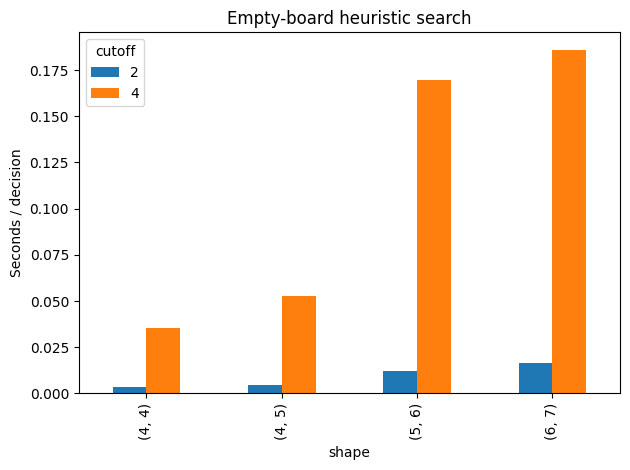

In [7]:
size_rows = []
for shape in ((4, 4), (4, 5), (5, 6), (6, 7)):
    for cutoff in (2, 4):
        board = empty_board(shape)
        search.heuristic_alpha_beta_search(board, cutoff=cutoff)
        size_rows.append({'shape': str(shape), 'cutoff': cutoff,
                          **search.heuristic_alpha_beta_search(board, cutoff=cutoff)})
heuristic_sizes = pd.DataFrame(size_rows)
display(heuristic_sizes)
heuristic_sizes.pivot(index='shape', columns='cutoff', values='elapsed_s').plot.bar(
    ylabel='Seconds / decision', title='Empty-board heuristic search')
plt.tight_layout(); plt.show()

### Hai cutoff thi đấu

Chạy một ván cutoff 2 làm +1 và cutoff 4 làm −1, rồi đổi bên một lần để thấy ảnh hưởng vai. Agent xác định nên không lặp lại nhiều bản sao của cùng ván.

In [8]:
cutoff_matches = pd.DataFrame([
    {'p1_cutoff': 2, 'p2_cutoff': 4, **run_matches(search.HeuristicAlphaBetaAgent(2), search.HeuristicAlphaBetaAgent(4))},
    {'p1_cutoff': 4, 'p2_cutoff': 2, **run_matches(search.HeuristicAlphaBetaAgent(4), search.HeuristicAlphaBetaAgent(2))},
])
display(cutoff_matches)

,p1_cutoff,p2_cutoff,p1_wins,draws,p2_wins,p1_moves,p2_moves,p1_total_s,p2_total_s,p1_mean_ms,p2_mean_ms
0,2,4,1,0,0,9,8,0.325924,3.686583,36.213822,460.822888
1,4,2,0,0,1,18,18,6.893736,0.419370,382.985328,23.298317


### Nhận xét

Cutoff lớn xem xa hơn nhưng chi phí tăng; heuristic vẫn có thể mắc lỗi ở chân trời tìm kiếm. Hai ván đổi vai cho biết kết quả đúng cặp cấu hình này, không đủ kết luận cutoff 4 luôn mạnh hơn.

Lần chạy này cutoff 2 thắng cả khi làm +1 và −1. Kết quả cho thấy tìm sâu hơn với cùng heuristic không tự động tạo agent mạnh hơn; cần đánh giá nhiều vị trí và đối thủ trước khi khái quát.

## Task 5 — Pure Monte Carlo Search

Import `playout`, `pmcs`, `PureMonteCarloAgent`. Tổng ngân sách chia đều cho các nước hợp lệ, dư tối đa một lượt mỗi nước. Rollout chọn ngẫu nhiên đến terminal và trả utility theo người gốc. Kiểm tra thắng ngay là shortcut chiến thuật tường minh, không phải bằng chứng sức mạnh rollout. Đo trên đúng năm fixture Task 4, seed 42.

,state,N,move,value,playouts,elapsed_s
0,horizontal win,10,3,1.000000,10,0.034830
1,horizontal win,100,3,1.000000,100,0.362527
2,horizontal win,1000,3,1.000000,1000,3.123056
3,vertical win,10,2,1.000000,10,0.034042
4,vertical win,100,2,1.000000,100,0.348642
5,vertical win,1000,2,1.000000,1000,2.479316
6,block horizontal,10,3,1.000000,10,0.017609
7,block horizontal,100,3,0.600000,100,0.212599
8,block horizontal,1000,3,0.580420,1000,2.242634
9,diagonal win,10,3,1.000000,10,0.011455


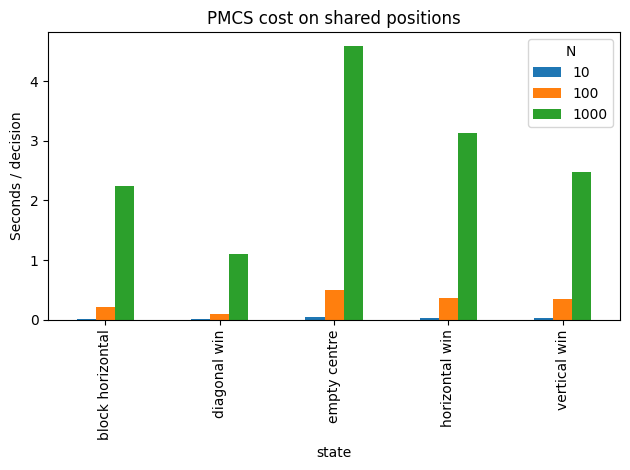

In [9]:
pmcs_rows = []
for name, (board, player) in positions.items():
    for budget in (10, 100, 1000):
        pmcs(board, player, budget, SEED)  # warm-up
        original = board.copy()
        found = pmcs(board, player, budget, SEED)
        assert np.array_equal(board, original)
        assert found['move'] in actions(board) and found['playouts'] == budget
        pmcs_rows.append({'state': name, 'N': budget, 'move': found['move'], 'value': found['value'],
                          'playouts': found['playouts'], 'elapsed_s': found['elapsed_s']})
pmcs_results = pd.DataFrame(pmcs_rows)
display(pmcs_results)
pmcs_results.pivot(index='state', columns='N', values='elapsed_s').plot.bar(
    ylabel='Seconds / decision', title='PMCS cost on shared positions')
plt.tight_layout(); plt.show()

### So sánh chất lượng và kết luận

Heuristic Alpha-Beta tìm phản ứng tối ưu của đối thủ trong phần cây đã mở, còn PMCS ước lượng kết quả trước đối thủ ngẫu nhiên. PMCS có thể bỏ sót một nước chặn duy nhất dù utility trung bình khá cao; tăng N giảm nhiễu nhưng không đổi mô hình đối thủ. Heuristic phụ thuộc cutoff và hàm đánh giá; PMCS không cần heuristic vị trí nhưng tốn nhiều rollout. Ở nước thắng ngay, PMCS dùng shortcut đã công bố, nên thành công đó không đo riêng khả năng thống kê. Bảng fixture chỉ so sánh quyết định; không có giải đấu trực tiếp cùng thời gian nên chưa kết luận thuật toán nào mạnh hơn.

**Tích hợp:** đọc kết quả bàn giao của Thiện trực tiếp từ file results, không sửa file đó. Kết quả Hải và kiểm thử với core được tích hợp khi có file; hiện ghi thiếu rõ ràng, không tạo số liệu thay.

Trên bàn rỗng seed 42, PMCS N=10/100/1000 lần lượt chọn cột 5/1/3. Các thế thắng ngay đều được nhận ra nhờ shortcut; thế cần chặn chọn cột 3 ở cả ba ngân sách. Heuristic cutoff 2 và 4 cũng chọn cột 3 ở thế chặn. Đây là đối chiếu quyết định cụ thể, không thay giải đấu cùng ngân sách thời gian.

In [10]:
for owner in ('hai', 'thien'):
    path = Path(f'results/{owner}_results.md')
    if path.exists():
        display(Markdown(path.read_text(encoding='utf-8')))
    else:
        display(Markdown(f'Chưa nhận bàn giao: `{path.as_posix()}`.'))

def markdown_table(frame):
    rows = ['|' + '|'.join(map(str, frame.columns)) + '|', '|' + '|'.join(['---'] * len(frame.columns)) + '|']
    for row in frame.itertuples(index=False, name=None):
        rows.append('|' + '|'.join(f'{v:.6f}' if isinstance(v, float) else str(v) for v in row) + '|')
    return '\n'.join(rows)

summary = ('## Connect 4 — tích hợp của Ly\n\nBackend: ' + RULES_BACKEND + '.\n\n'
    'Seed 42; Random vs Random 1000; Alpha-Beta vs Random 10 ván mỗi vai trên 4x4; '
    'hai cutoff đổi vai một lần trên 6x7. Timing không gồm render, TB/nước tính bằng tổng giây / số nước của từng bên.\n\n'
    '### Random vs Random\n' + markdown_table(random_results)
    + '\n\n### Full Alpha-Beta / ordering\n' + markdown_table(exact_results)
    + '\n\n### Kích thước bàn, full search cuối ván (4 ô trống)\n' + markdown_table(scaling_results)
    + '\n\n### Alpha-Beta vs Random\n' + markdown_table(ab_matches)
    + '\n\n### Heuristic trên năm fixture\n' + markdown_table(heuristic_results)
    + '\n\n### Heuristic bàn rỗng theo kích thước\n' + markdown_table(heuristic_sizes)
    + '\n\n### Cutoff 2 vs 4\n' + markdown_table(cutoff_matches)
    + '\n\n### PMCS trên cùng năm fixture\n' + markdown_table(pmcs_results)
    + '\n\nKhông suy ra sức mạnh tổng quát từ fixture. Full search chỉ dùng 4x4 hoặc cuối ván; '
    'không giải bàn rỗng 6x7. Monte Carlo dùng random opponent model, có shortcut thắng ngay. '
    'Core chính thức và kết quả Hải còn thiếu: cần chạy lại notebook và test khi Hải bàn giao.\n')
path = Path('results/ly_results.md')
old = path.read_text(encoding='utf-8') if path.exists() else '# Kết quả cá nhân — Ly\n'
begin, end = '<!-- BEGIN CONNECT4 -->', '<!-- END CONNECT4 -->'
block = begin + '\n' + summary + '\n' + end
if begin in old:
    start, stop = old.index(begin), old.index(end) + len(end)
    old = old[:start] + block + old[stop:]
else:
    old += '\n' + block + '\n'
path.parent.mkdir(exist_ok=True)
path.write_text(old, encoding='utf-8')
print('Updated results/ly_results.md')

Chưa nhận bàn giao: `results/hai_results.md`.

# Kết quả cá nhân — Thiện

## Protocol

- Seed mặc định: `42`; đồng hồ dùng `time.perf_counter()`.
- Node counter được tạo mới cho từng lần search. Thời gian là thời gian của một lần gọi search, không gồm render bảng/Matplotlib hoặc kiểm tra hậu nghiệm tập nước đi tối ưu.
- `Tổng thời gian` ở các trận đấu là tổng mọi lần agent chọn nước; `TB/nước agent = tổng thời gian / số nước agent`, **không** phải tổng thời gian chia số ván.
- Số mili-giây thay đổi theo máy và tải nền; node/value/move mới là các chỉ số tái lập chính.

## Tic-Tac-Toe — Minimax và Alpha-Beta

|Trạng thái|Minimax: move/value/nodes/ms|Alpha-Beta: move/value/nodes/ms|
|---|---:|---:|
|T1 X sắp thắng|2 / 1 / 190 / 9.494|2 / 1 / 61 / 3.156|
|T2 X cần hòa|7 / 0 / 206 / 10.616|7 / 0 / 101 / 4.982|
|T3 bất lợi|1 / -1 / 941 / 46.387|1 / -1 / 238 / 11.843|
|T4 bàn rỗng|0 / 0 / 549,946 / 26,517.475|0 / 0 / 18,297 / 1,008.932|

Khẳng định đã chạy: hai thuật toán luôn cùng giá trị **và cùng tập nước đi tối ưu**. Các tập tương ứng T1 `(2,6,8)`, T2 `(7,)`, T3 `(1,3,4,5,6,7)`, T4 `(0..8)`; vì vậy không ép hai thuật toán phải chọn cùng chỉ số khi có hòa.

### Alpha-Beta: ordering off/on

|Trạng thái|Off nodes/ms|On (giữa→góc→cạnh) nodes/ms|Thay đổi node|
|---|---:|---:|---:|
|T1|61 / 3.205|44 / 2.280|-27.9%|
|T2|101 / 5.995|149 / 7.576|+47.5%|
|T3|238 / 12.048|51 / 2.394|-78.6%|
|T4|18,297 / 875.534|7,275 / 363.398|-60.2%|

Ordering tĩnh không bảo đảm luôn tốt: T2 tăng node. Tuy vậy ở bàn rỗng và T3 nó giảm đáng kể vì nước tốt được duyệt sớm, tạo cận alpha/beta để cắt nhánh.

## Tic-Tac-Toe — heuristic Alpha-Beta

|Trạng thái|Full: move/value/nodes/ms|cutoff 2: move/value/nodes/ms|cutoff 4: move/value/nodes/ms|
|---|---:|---:|---:|
|T1|2 / 1 / 44 / 1.090|8 / 1 / 14 / 1.037|2 / 1 / 36 / 1.843|
|T2|7 / 0 / 149 / 3.293|7 / -0.13 / 26 / 2.007|7 / -0.05 / 120 / 7.140|
|T3|4 / -1 / 51 / 2.617|4 / -0.23 / 17 / 2.390|4 / -1 / 35 / 2.935|
|T4|4 / 0 / 7,275 / 429.053|4 / 0.11 / 26 / 5.629|4 / 0.05 / 283 / 58.420|

Trên bộ T1–T4 này, tất cả nước cutoff đều thuộc tập nước tối ưu của full search. Tuy nhiên giá trị heuristic ở cutoff khác utility cuối ván (ví dụ T2/T4), nên đây không phải bảo đảm tổng quát về chất lượng.

|Agent|Vai|Thắng/Hòa/Thua|Nước agent|Tổng thời gian (s)|TB/nước agent (ms)|
|---|---|---:|---:|---:|---:|
|Heuristic AB cutoff=2|X|96 / 4 / 0|328|1.5233|4.6443|
|Heuristic AB cutoff=2|O|89 / 11 / 0|322|1.1211|3.4816|
|Heuristic AB cutoff=4|X|96 / 4 / 0|378|11.7614|31.1149|
|Heuristic AB cutoff=4|O|83 / 17 / 0|351|8.7444|24.9128|

## Connect 4 search

`connect4_search.py` cài Alpha-Beta exact (chỉ dùng full search cho 4×4), ordering tâm bàn, heuristic cửa sổ 4 ô và cutoff. `evaluate` dành ±1 cho terminal và chuẩn hóa non-terminal bằng `tanh`, nên luôn thuộc `[-1, 1]`.

Các test thủ công trong `tests/test_connect4_search.py`: thắng ngay, chặn thua, thắng ngang, thắng dọc, thắng chéo được đỡ quân, và ưu tiên tâm bàn. Test cũng kiểm tra range heuristic, schema metrics, callable agents và không mutate input.

|Thí nghiệm|Cấu hình|Move/value|Nodes|Thời gian (ms)|
|---|---|---:|---:|---:|
|Full Alpha-Beta bàn rỗng 4×4|ordering off|0 / 0|62,889|1,937.713|
|Full Alpha-Beta bàn rỗng 4×4|ordering centre-first|1 / 0|155,968|5,324.759|
|Heuristic AB bàn rỗng 6×7|cutoff=2|3 / -0.045|24|14.274|
|Heuristic AB bàn rỗng 6×7|cutoff=4|3 / -0.030|234|96.404|
|Heuristic AB bàn rỗng 6×7|cutoff=6|3 / -0.033|1,458|541.534|

Ở đúng bàn rỗng 4×4 này, centre-first tệ hơn thứ tự cột tự nhiên; đó là kết quả hợp lệ của static ordering, không phải lỗi correctness. Vì game tree 6×7 có branching factor gần 7 và độ sâu tối đa 42, không dùng full Alpha-Beta ở 6×7; cutoff/heuristic là bắt buộc để thời gian phản hồi thực tế.

## Kiểm thử

```text
python -m pytest tests/test_connect4_search.py -q
7 passed
```

Hai notebook đã chạy từ kernel mới bằng `jupyter nbconvert --to notebook --execute --inplace ...` và không có traceback.


Updated results/ly_results.md
